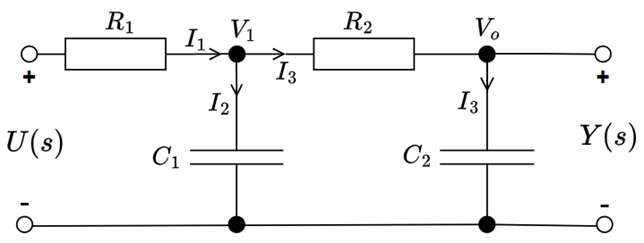

            พลานต์ (Plant) อันดับสองจากวงจร RC แบบสองขั้น

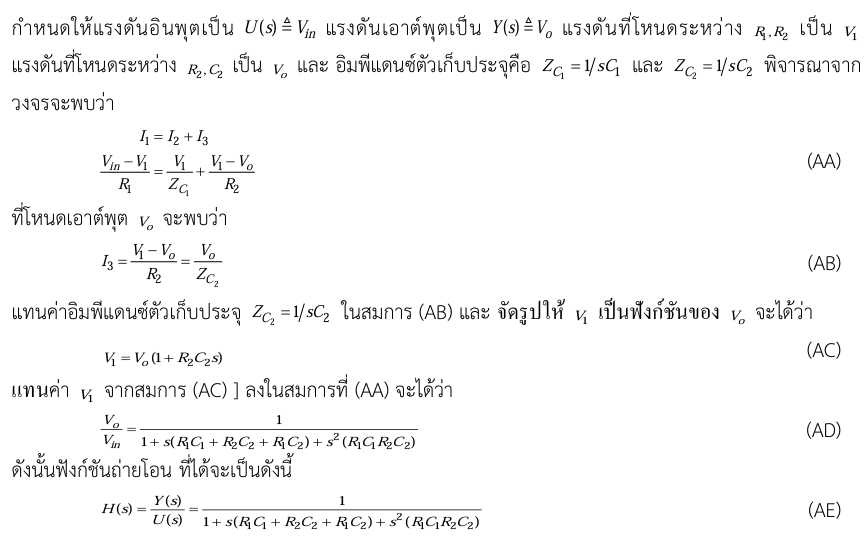

อนึ่ง สามารถใช้ google Colab เขียนโค๊ด python ในสไตน์  .ipynb เพื่อช่วยหาฟังก์ชันถ่ายโอน ได้ดังนี้

In [1]:
import sympy as sp

# ประกาศตัวแปรเชิงสัญลักษณ์
R1, R2, C1, C2, s, U, Y = sp.symbols('R1 R2 C1 C2 s U Y')

# นิยามแรงดันโหนดกลาง V1 จาก KCL ที่เอาต์พุต
V1 = Y * (1 + s*R2*C2)

# KCL ที่โหนด V1:
# (U - V1)/R1 = s*C1*V1 + (V1 - Y)/R2
expr = sp.Eq((U - V1)/R1, s*C1*V1 + (V1 - Y)/R2)

# แก้สมการหา Y ในรูปของ U
Ysol = sp.solve(expr, Y)[0]

# ฟังก์ชันถ่ายโอน H(s) = Y/U
Hs = sp.simplify(Ysol / U)

print("H(s) =", Hs)

# Extract the denominator of H(s)
denom_Hs = sp.denom(Hs)

# The standard form of a second-order transfer function is H(s) = K * ωn^2 / (s^2 + 2ζωn*s + ωn^2)
# First, normalize the denominator by dividing by the coefficient of s^2
# to match the standard form: s^2 + (2ζωn)*s + ωn^2

# Extract coefficients of s^2, s, and constant from the denominator
poly_denom = sp.Poly(denom_Hs, s)
coeffs = poly_denom.coeffs()

a = coeffs[0]  # Coefficient of s^2
b = coeffs[1]  # Coefficient of s
c = coeffs[2]  # Constant term

# Calculate natural frequency (ωn)
# ωn^2 = c/a => ωn = sqrt(c/a)
omega_n = sp.sqrt(c/a)
print("\nNatural Frequency (ωn) =", sp.simplify(omega_n))

# Calculate damping ratio (ζ)
# 2ζωn = b/a => ζ = (b/a) / (2ωn)
damping_ratio = (b/a) / (2 * omega_n)
print("Damping Ratio (ζ) =", sp.simplify(damping_ratio))

H(s) = 1/(C1*C2*R1*R2*s**2 + C1*R1*s + C2*R1*s + C2*R2*s + 1)

Natural Frequency (ωn) = sqrt(1/(C1*C2*R1*R2))
Damping Ratio (ζ) = sqrt(1/(C1*C2*R1*R2))*(C1*R1 + C2*R1 + C2*R2)/2


---
# ส่วนที่ 2: จากแบบจำลองสู่การทำนายผลการทดลอง (ต่อยอดสำหรับบทความ)

ขั้นตอนในส่วนนี้

1. แทน $R_1=R_2=R$, $C_1=C_2=C$ ในฟังก์ชันถ่ายโอนเชิงสัญลักษณ์ แล้วหา $\omega_n$, $\zeta$, ราก (โพล) และค่าคงตัวเวลา
2. แทนค่าจริง $R=500\,\Omega$, $C=22\,\mu F$ และหาผลตอบสนองวงเปิด ($t_r$, $t_s$)
3. ต่อตัวควบคุม PID ($K_c=0.8$, $T_i=2$ s, $T_d=0.01$ s) แล้วหาโพลของระบบวงปิดและโพลเด่น
4. พิสูจน์สมการประมาณ (13) ด้วย SymPy และหาสูตรทำนาย $t_r$, $t_s$, IAE, ISE, $y(0^+)$
5. เทียบค่าทำนายกับการจำลองวงปิดเต็มรูป
6. จำลองตัวควบคุมดิจิทัล Simple PID กับ Tustin PID แบบเดียวกับเฟิร์มแวร์ (ที่ $T_s = 1.024$ ms) และพิสูจน์ว่าผลต่างของเทอมอินทิกรัลไม่เกินประมาณ $2\times10^{-4}$


In [2]:
# ---------- 2.1 กรณีวงจรสมมาตร R1 = R2 = R, C1 = C2 = C ----------
R, C = sp.symbols('R C', positive=True)
Hs_sym = sp.simplify(Hs.subs({R1: R, R2: R, C1: C, C2: C}))
print("H(s) =", Hs_sym)

den_sym = sp.Poly(sp.denom(Hs_sym), s)
a2, a1, a0 = den_sym.all_coeffs()
wn_sym   = sp.simplify(sp.sqrt(a0/a2))
zeta_sym = sp.simplify((a1/a2)/(2*wn_sym))
print("ωn =", wn_sym, "   ζ =", zeta_sym)
print("โพล (เชิงสัญลักษณ์):", [sp.simplify(p) for p in sp.solve(sp.denom(Hs_sym), s)])


H(s) = 1/(C**2*R**2*s**2 + 3*C*R*s + 1)
ωn = 1/(C*R)    ζ = 3/2
โพล (เชิงสัญลักษณ์): [(-3 - sqrt(5))/(2*C*R), (-3 + sqrt(5))/(2*C*R)]


ผลข้างบนแสดงว่าเมื่อ $R_1=R_2=R$ และ $C_1=C_2=C$:

$$G(s)=\frac{1}{(RC)^2 s^2 + 3RC\,s + 1},\qquad \omega_n=\frac{1}{RC},\qquad \zeta=\frac{3}{2}$$

ค่า $\zeta = 1.5$ ไม่ขึ้นกับค่า R และ C เลย วงจร RC สองขั้นแบบสมมาตรจึง **overdamped เสมอ**


RC = 11.0 ms,  ωn = 90.91 rad/s,  ζ = 1.50  -> overdamped
โพลของพลานต์ (rad/s): [-238.003  -34.724]
ค่าคงตัวเวลา (ms): [ 4.2 28.8]
วงเปิด: tr (10–90%) = 64.4 ms,  ts (±2%) = 117.2 ms
tr/Ts ≈ 63 เท่า,  ts/Ts ≈ 114 เท่า


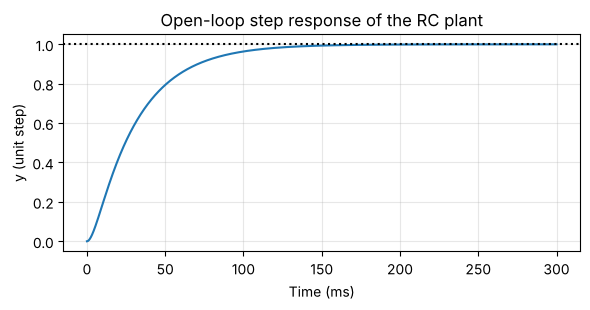

In [3]:
# ---------- 2.2 แทนค่าจริงและหาลักษณะผลตอบสนองวงเปิด ----------
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

Rv, Cv = 500.0, 22e-6
RC = Rv*Cv
wn   = float(wn_sym.subs({R: Rv, C: Cv}))
zeta = float(zeta_sym)
num_G = [1.0]
den_G = [RC**2, 3*RC, 1.0]
poles_G = np.roots(den_G)
tau_G = -1/poles_G

print(f"RC = {RC*1e3:.1f} ms,  ωn = {wn:.2f} rad/s,  ζ = {zeta:.2f}  ->",
      "overdamped" if zeta > 1 else ("critically damped" if zeta == 1 else "underdamped"))
print("โพลของพลานต์ (rad/s):", np.round(np.sort(poles_G), 3))
print("ค่าคงตัวเวลา (ms):", np.round(np.sort(tau_G)*1e3, 2))

def step_info(t, y, yfinal, band=0.02):
    i10 = np.argmax(y >= 0.1*yfinal); i90 = np.argmax(y >= 0.9*yfinal)
    out = np.where(np.abs(y - yfinal) > band*abs(yfinal))[0]
    return t[i90] - t[i10], t[out[-1]] if len(out) else 0.0

G = signal.TransferFunction(num_G, den_G)
t_ol = np.linspace(0, 0.3, 30001)
_, y_ol = signal.step(G, T=t_ol)
tr_ol, ts_ol = step_info(t_ol, y_ol, 1.0)
Ts = 1.024e-3
print(f"วงเปิด: tr (10–90%) = {tr_ol*1e3:.1f} ms,  ts (±2%) = {ts_ol*1e3:.1f} ms")
print(f"tr/Ts ≈ {tr_ol/Ts:.0f} เท่า,  ts/Ts ≈ {ts_ol/Ts:.0f} เท่า")

plt.figure(figsize=(6, 3.2))
plt.plot(t_ol*1e3, y_ol)
plt.axhline(1, ls=':', c='k')
plt.xlabel('Time (ms)'); plt.ylabel('y (unit step)'); plt.title('Open-loop step response of the RC plant')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()


## 2.3 ระบบวงปิดกับตัวควบคุม PID

ตัวควบคุม $C(s)=K_c\left(1+\dfrac{1}{T_i s}+T_d s\right)=\dfrac{K_d s^2 + K_c s + K_i}{s}$ โดย $K_i = K_c/T_i$, $K_d = K_c T_d$

ระบบวงปิด $T(s)=\dfrac{C(s)G(s)}{1+C(s)G(s)}$


In [4]:
# ---------- 2.3 โพลของระบบวงปิด ----------
Kc, Ti, Td = 0.8, 2.0, 0.01
Ki, Kd = Kc/Ti, Kc*Td

num_C = [Kd, Kc, Ki]                   # (Kd s^2 + Kc s + Ki)/s
den_L = np.polymul([1, 0], den_G)       # s * plant denominator
num_T = num_C
den_T = np.polyadd(den_L, num_C)
T_cl = signal.TransferFunction(num_T, den_T)

poles_T = np.sort(np.roots(den_T))
p_dom_pred = -Ki/(1 + Kc)
tau = (1 + Kc)/Ki
print("โพลของระบบวงปิด (rad/s):", np.round(poles_T, 4))
print(f"โพลเด่นที่ทำนาย -Ki/(1+Kc) = {p_dom_pred:.4f} rad/s")
print(f"ค่าคงตัวเวลาเด่นของระบบวงปิด τ = (1+Kc)Ti/Kc = {tau:.2f} s")
print(f"τ / Ts ≈ {tau/Ts:.0f} เท่า")


โพลของระบบวงปิด (rad/s): [-2.870613e+02 -5.155830e+01 -2.234000e-01]
โพลเด่นที่ทำนาย -Ki/(1+Kc) = -0.2222 rad/s
ค่าคงตัวเวลาเด่นของระบบวงปิด τ = (1+Kc)Ti/Kc = 4.50 s
τ / Ts ≈ 4395 เท่า


## 2.4 พิสูจน์สมการ (13) ด้วย SymPy

สมมติฐาน: พลานต์เร็วกว่าระบบวงปิดมาก จึงประมาณ $G(s)\approx1$ ($y\approx u$) และละเทอม D

$$y = K_c e + K_i\!\int e\,dt,\quad e = r - y \;\Rightarrow\; (1+K_c)\,\dot e + K_i e = 0$$

ที่ $t=0^+$ อินทิกรัลเป็นศูนย์ จึงได้ $e(0^+) = r/(1+K_c)$


In [5]:
# ---------- 2.4 แก้สมการเชิงอนุพันธ์และหาสูตรทำนาย ----------
t, r_, Kc_, Ki_ = sp.symbols('t r K_c K_i', positive=True)
e = sp.Function('e')
ode = sp.Eq((1 + Kc_)*e(t).diff(t) + Ki_*e(t), 0)
e_sol = sp.dsolve(ode, e(t), ics={e(0): r_/(1 + Kc_)}).rhs
y_sol = sp.simplify(r_ - e_sol)
tau_s = (1 + Kc_)/Ki_
print("e(t) =", e_sol)
print("y(t) =", y_sol)

# tr: เวลาที่ y = 0.9r (ที่ t=0+ y ≈ 0.44r > 0.1r อยู่แล้ว)
t90 = sp.solve(sp.Eq(y_sol, sp.Rational(9, 10)*r_), t)[0]
# ts: เวลาที่ |e| = 0.02 r
t_s = sp.solve(sp.Eq(e_sol, sp.Rational(2, 100)*r_), t)[0]
IAE = sp.integrate(e_sol, (t, 0, sp.oo))
ISE = sp.integrate(e_sol**2, (t, 0, sp.oo))
y0  = sp.limit(y_sol, t, 0, '+')

for name, ex in [("tr", t90), ("ts", t_s), ("IAE", IAE), ("ISE", ISE), ("y(0+)", y0)]:
    print(f"{name:6s} =", sp.simplify(sp.expand_log(ex, force=True)))


e(t) = r*exp(-K_i*t/(K_c + 1))/(K_c + 1)
y(t) = r - r*exp(-K_i*t/(K_c + 1))/(K_c + 1)


tr     = -(K_c + 1)*(log(K_c + 1) - log(10))/K_i
ts     = -(K_c + 1)*(log(K_c + 1) - log(50))/K_i
IAE    = r/K_i
ISE    = r**2/(2*K_i*(K_c + 1))
y(0+)  = K_c*r/(K_c + 1)


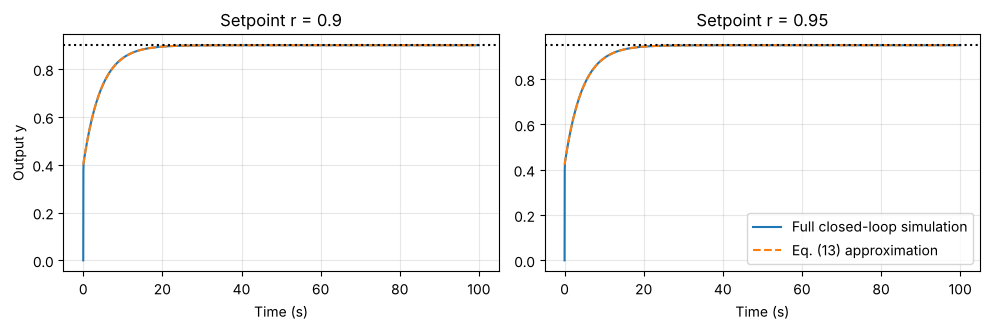

,r,quantity,prediction,full_simulation,diff_percent
0,0.9000,tr,7.7166,7.6882,-0.3679
1,0.9000,ts,14.9591,14.8956,-0.4242
2,0.9000,IAE,2.2500,2.2500,0.0020
3,0.9000,ISE,0.5625,0.5688,1.1124
4,0.9000,y0,0.4000,0.4083,2.0784
5,0.9500,tr,7.7166,7.6882,-0.3679
6,0.9500,ts,14.9591,14.8956,-0.4242
7,0.9500,IAE,2.3750,2.3750,0.0020
8,0.9500,ISE,0.6267,0.6337,1.1124
9,0.9500,y0,0.4222,0.4310,2.0784


In [6]:
# ---------- 2.5 เทียบค่าทำนายกับการจำลองวงปิดเต็มรูป ----------
import pandas as pd

subs = {Kc_: Kc, Ki_: Ki}
dt = 1e-4
t_sim = np.arange(0, 100 + dt, dt)
rows = []
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for k, r in enumerate([0.9, 0.95]):
    _, yF = signal.step(T_cl, T=t_sim); yF = r*yF
    eF = r - yF
    trF, tsF = step_info(t_sim, yF, r)
    sim = dict(tr=trF, ts=tsF, IAE=np.sum(np.abs(eF))*dt, ISE=np.sum(eF**2)*dt,
               y0=yF[np.argmax(t_sim >= 0.1)])
    pred = dict(tr=float(t90.subs(subs)), ts=float(t_s.subs(subs)),
                IAE=float(IAE.subs({**subs, r_: r})), ISE=float(ISE.subs({**subs, r_: r})),
                y0=float(y0.subs({**subs, r_: r})))
    for q in pred:
        rows.append(dict(r=r, quantity=q, prediction=pred[q], full_simulation=sim[q],
                         diff_percent=100*(sim[q]-pred[q])/pred[q]))
    yA = np.array([float(y_sol.subs({**subs, r_: r, t: tt})) for tt in t_sim[::1000]])
    axs[k].plot(t_sim[::100], yF[::100], label='Full closed-loop simulation')
    axs[k].plot(t_sim[::1000], yA, '--', label='Eq. (13) approximation')
    axs[k].axhline(r, ls=':', c='k')
    axs[k].set_title(f'Setpoint r = {r}'); axs[k].set_xlabel('Time (s)'); axs[k].grid(alpha=.3)
axs[0].set_ylabel('Output y'); axs[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

df = pd.DataFrame(rows)
pd.options.display.float_format = '{:.4f}'.format
display(df)


## 2.6 ตัวควบคุมดิจิทัล: Simple PID เทียบกับ Tustin PID

จำลองแบบเดียวกับเฟิร์มแวร์

- พลานต์ถูกแปลงเป็นแบบไม่ต่อเนื่องด้วย ZOH ที่คาบของฮาร์ดแวร์ $T_s = 1.024$ ms
- ตัวควบคุมใช้ $f_s = 976.165$ Hz ในสมการ เหมือนโค้ดจริง
- ใส่ความละเอียดของ ADC 10 บิตและ PWM 8 บิต ส่วนสัญญาณควบคุมจำกัดอยู่ในช่วง [0, 1]
- `delay=1` จำลองสถาปัตยกรรม Timer-based ซึ่งใช้ค่า ADC ของรอบก่อน

**ข้อควรรู้:** การจำลองนี้ไม่มีสัญญาณรบกวนในการวัด และไม่มี jitter จึงใช้ดูผลของ "สูตร" และ "โครงสร้างเวลา" ในอุดมคติเท่านั้น ไม่ได้จำลองทุกอย่างที่เกิดในฮาร์ดแวร์จริง


In [7]:
# ---------- 2.6 จำลอง Simple / Tustin PID แบบเฟิร์มแวร์ ----------
Ts_hw  = 1.024e-3
Ts_pid = 1/976.165
Ad, Bd, Cd, Dd, _ = signal.cont2discrete(signal.tf2ss(num_G, den_G), Ts_hw, method='zoh')
N = int(round(100/Ts_hw))            # 100 s = 97,656 รอบ

a11, a12, a21, a22 = Ad.ravel(); b1, b2 = Bd.ravel(); c1, c2 = Cd.ravel()   # ใช้สเกลาร์เพื่อความเร็ว

def run(alg, r, delay=0, quant=True):
    x1 = x2 = 0.0; ui = ui_1 = e_1 = 0.0
    y_hist = np.zeros(N); u_hist = np.zeros(N); e_hist = np.zeros(N)
    y_meas_prev = 0.0
    for k in range(N):
        y_true = c1*x1 + c2*x2
        y_now = round(y_true*1023)/1023 if quant else y_true
        y_meas = y_meas_prev if delay else y_now     # Timer-based: ใช้ค่าของรอบก่อน
        y_meas_prev = y_now
        e = r - y_meas
        if alg == 'SIMPLE':
            ui = min(max(ui + Ki*Ts_pid*e, -1), 1)
            ud = Kd*(e - e_1)/Ts_pid
            u = Kc*e + ui + ud
        else:
            ui = min(max(ui_1 + Kc/Ti*Ts_pid/2*(e + e_1), -1), 1)
            ud = Kc*Td/Ts_pid*(e - e_1)
            u = Kc*e + ui + ud
            ui_1 = ui
        e_1 = e
        u = min(max(u, 0.0), 1.0)
        if quant: u = int(u*255 + 0.5)/255
        x1, x2 = a11*x1 + a12*x2 + b1*u, a21*x1 + a22*x2 + b2*u
        y_hist[k], u_hist[k], e_hist[k] = y_true, u, e
    return y_hist, u_hist, e_hist

t_d = np.arange(N)*Ts_hw
rows = []
for r in [0.9, 0.95]:
    for alg in ['TUSTIN', 'SIMPLE']:
        for delay, arch in [(0, 'ADC-based (ideal)'), (1, 'Timer-based (ideal)')]:
            y, u, e = run(alg, r, delay)
            tr_, ts_ = step_info(t_d, y, r)
            rows.append(dict(r=r, structure=f'{alg.title()} & {arch}',
                             RMS=np.sqrt(np.mean(e**2)), IAE=np.sum(np.abs(e))*Ts_hw,
                             ISE=np.sum(e**2)*Ts_hw, tr=tr_, ts=ts_))
display(pd.DataFrame(rows))


,r,structure,RMS,IAE,ISE,tr,ts
0,0.9000,Tustin & ADC-based (ideal),0.0756,2.2765,0.5714,7.6657,14.6893
1,0.9000,Tustin & Timer-based (ideal),0.0756,2.2767,0.5717,7.6544,14.6862
2,0.9000,Simple & ADC-based (ideal),0.0756,2.2765,0.5714,7.6657,14.6903
3,0.9000,Simple & Timer-based (ideal),0.0756,2.2767,0.5717,7.6544,14.6872
4,0.9500,Tustin & ADC-based (ideal),0.0798,2.3915,0.6367,7.7138,14.9187
5,0.9500,Tustin & Timer-based (ideal),0.0798,2.3915,0.6371,7.6954,14.9422
6,0.9500,Simple & ADC-based (ideal),0.0798,2.3915,0.6367,7.7138,14.9187
7,0.9500,Simple & Timer-based (ideal),0.0798,2.3915,0.6370,7.6974,14.9432


ในการจำลองแบบอุดมคติ (ไม่มีสัญญาณรบกวนและ jitter) ทั้ง 4 โครงสร้างให้ผลแทบเท่ากัน ซึ่งสอดคล้องกับผลการทดลองที่พบว่าอัลกอริทึมไม่มีผลอย่างมีนัยสำคัญ

ส่วนความต่างของสถาปัตยกรรมที่วัดได้จริงในการทดลอง (RMS Error ต่ำกว่า 2.2–2.5%) ไม่ปรากฏในการจำลองนี้ จึงชี้ว่าความต่างดังกล่าวมาจากปัจจัยที่แบบจำลองไม่ได้รวมไว้ เช่น สัญญาณรบกวนในการวัด และจังหวะการแปลง ADC เทียบกับกิจกรรมอื่นของชิป ข้อนี้ตรงกับการอภิปรายในหัวข้อ 3.3 ของบทความ


## 2.7 พิสูจน์ขอบเขตผลต่างของเทอมอินทิกรัล

จากผลรวมแบบยุบตัว (telescoping sum)

$$U_I^{T}(k)-U_I^{S}(k)=\frac{K_iT_s}{2}\big[E(0)-E(k)\big]\quad\Rightarrow\quad |\Delta U_I|\le \frac{K_iT_s}{2}\max|E|\approx 2\times10^{-4}$$

เซลล์ข้างล่างตรวจสมการนี้ด้วยตัวเลข โดยใช้ลำดับความคลาดเคลื่อน $E(k)$ ชุดเดียวกันป้อนให้ทั้งสองสูตร


max |ΔU_I| (ตัวเลข)        = 1.946e-04
max |สูตร KiTs[E(0)-E(k)]/2| = 1.946e-04
ผลต่างระหว่างตัวเลขกับสูตร   = 4.6e-15  (ระดับความละเอียดของเลขทศนิยม)
ขอบเขต KiTs·0.95/2           = 1.946e-04
ความละเอียด PWM 1/255         = 3.922e-03  → ห่างกัน 20 เท่า


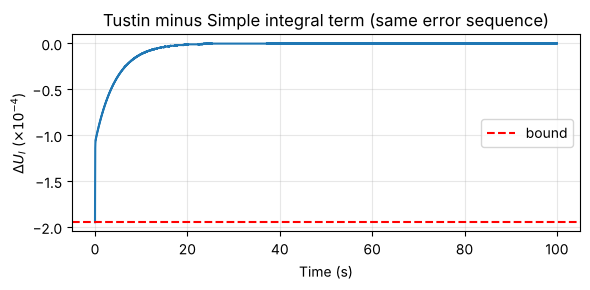

In [8]:
# ---------- 2.7 ตรวจผลต่างของเทอมอินทิกรัล ----------
_, _, E = run('SIMPLE', 0.95, delay=0)          # ใช้ลำดับ E(k) จากการจำลองจริง
E0 = 0.0                                          # e_1 เริ่มต้นในเฟิร์มแวร์ = 0
UI_S = np.cumsum(Ki*Ts_pid*E)
UI_T = np.cumsum(Ki*Ts_pid/2*(E + np.concatenate(([E0], E[:-1]))))
dUI = UI_T - UI_S
closed_form = Ki*Ts_pid/2*(E0 - E)

print(f"max |ΔU_I| (ตัวเลข)        = {np.max(np.abs(dUI)):.3e}")
print(f"max |สูตร KiTs[E(0)-E(k)]/2| = {np.max(np.abs(closed_form)):.3e}")
print(f"ผลต่างระหว่างตัวเลขกับสูตร   = {np.max(np.abs(dUI - closed_form)):.1e}  (ระดับความละเอียดของเลขทศนิยม)")
print(f"ขอบเขต KiTs·0.95/2           = {Ki*Ts_pid*0.95/2:.3e}")
print(f"ความละเอียด PWM 1/255         = {1/255:.3e}  → ห่างกัน {1/255/(Ki*Ts_pid*0.95/2):.0f} เท่า")

plt.figure(figsize=(6, 3))
plt.plot(np.arange(N)*Ts_hw, dUI*1e4)
plt.axhline(-Ki*Ts_pid*0.95/2*1e4, ls='--', c='r', label='bound')
plt.xlabel('Time (s)'); plt.ylabel(r'$\Delta U_I$ ($\times10^{-4}$)')
plt.title('Tustin minus Simple integral term (same error sequence)')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
